<center>
<h1><b>TP3 : Prompt Engineering</b></h1>
<h2><b>Classification tasks : Sentiment Analysis — avec Google Gemini</b></h2>
</center>

# Objectives

- Présenter les LLMs comme un outil efficace pour résoudre des problèmes de classification.
- Illustrer le *prompt engineering* pour l'analyse de sentiment (zero-shot, few-shot, Chain-of-Thought).
- Construire et évaluer des LLMs sur des tâches de classification plus larges (score **micro-F1**).

> **Choix du LLM :** ce TP utilise **Google Gemini** (via `langchain-google-genai`) à la place d'OpenAI.
> La clé API Gemini se crée gratuitement sur [Google AI Studio](https://aistudio.google.com/apikey).

## Plan du notebook

0. Préparer l'environnement
1. Tokenisation avec `tiktoken`
2. Utilisation d'un LLM : **Gemini** (LangChain)
3. *(Optionnel)* LLM via Ollama
4. Use case : **Sentiment Analysis**
   - Step 1 : Define Objectives and Metrics
   - Step 2 : Assemble Data
   - Step 3 : Élaborer les prompts (zero-shot, few-shot, CoT)
   - Step 4 : Evaluate Prompts
5. Synthèse des résultats

# 0. Préparer l'environnement

1. Ouvrir **VS Code**, créer un nouveau dossier (ex. **SMA_TokPr**) et ouvrir le terminal.
2. Installer **uv** :
   - macOS / Linux : `curl -LsSf https://astral.sh/uv/install.sh | sh`
   - Windows (PowerShell) : `powershell -ExecutionPolicy ByPass -c "irm https://astral.sh/uv/install.ps1 | iex"`
   Puis quitter et relancer VS Code.
3. Initialiser le projet : `uv init` (génère la structure du projet, notamment le fichier **pyproject.toml**).
4. Créer l'environnement virtuel : `uv venv`
5. Windows : autoriser PowerShell à exécuter les scripts
   `Set-ExecutionPolicy -ExecutionPolicy RemoteSigned -Scope Process`
   puis activer l'environnement : `.\.venv\Scripts\activate`
6. Installer les dépendances :
   ```
   uv add tiktoken langchain langchain-google-genai python-dotenv pandas numpy scikit-learn matplotlib tqdm session-info ipykernel
   ```
   *(si vous utilisez le dépôt fourni : `uv sync` suffit, tout est déjà déclaré dans `pyproject.toml`)*
7. Créer la clé API Gemini sur **https://aistudio.google.com/apikey**, puis créer un fichier **`.env`** à la racine :
   ```
   GOOGLE_API_KEY=votre_cle_gemini_ici
   ```
8. Ouvrir ce notebook, choisir le noyau (kernel) `.venv` et tester :

In [1]:
print("Bonjour")

Bonjour


# 1. Tokenisation avec `tiktoken`

Un LLM ne lit pas des mots mais des **tokens** (morceaux de mots). Le nombre de tokens détermine
le coût d'un appel et la place occupée dans la fenêtre de contexte.
`tiktoken` est la bibliothèque de tokenisation d'OpenAI (installée avec `uv add tiktoken`).

In [2]:
import tiktoken

In [3]:
tokenizer = tiktoken.encoding_for_model("gpt-4o")
print(tokenizer.name)

o200k_base


In [4]:
tokenizer = tiktoken.get_encoding("o200k_base")

In [5]:
prompt = "Vous êtes un expert en marketing digital. C'est quoi un digital marketer ? "

In [6]:
tokens = tokenizer.encode(prompt)
print(tokens)

[29038, 34077, 537, 8333, 469, 6686, 7058, 13, 363, 6616, 33399, 537, 7058, 95641, 1423, 220]


In [7]:
print(len(tokens))

16


In [8]:
# Affichage de chaque token, séparé par |
for token in tokens:
    t = tokenizer.decode_single_token_bytes(token).decode("utf-8", errors="replace")
    print(t, end="|")

Vous| êtes| un| expert| en| marketing| digital|.| C|'est| quoi| un| digital| marketer| ?| |

# 2. Utilisation des LLM : Google Gemini

Installer LangChain et l'intégration Gemini :
```
uv add langchain langchain-google-genai python-dotenv
```
La clé est lue automatiquement dans la variable d'environnement `GOOGLE_API_KEY` (fichier `.env`).

In [9]:
import os
from langchain_google_genai import ChatGoogleGenerativeAI
from langchain_core.rate_limiters import InMemoryRateLimiter
from dotenv import load_dotenv
from IPython.display import Markdown, display

In [10]:
load_dotenv(override=True)

True

In [12]:
# Vérification (sans afficher la clé !)
assert os.getenv("GOOGLE_API_KEY") or os.getenv("GEMINI_API_KEY"), \
    "Clé introuvable : créez un fichier .env contenant GOOGLE_API_KEY=..."
print("Clé API Gemini chargée ")

Clé API Gemini chargée 


### Configuration du modèle

- **Modèle :** `gemini-3.5-flash-lite` — modèle stable recommandé par Google pour les nouveaux projets,
  disponible dans l'offre gratuite avec le quota journalier le plus large. Ce TP envoie environ
  **460 requêtes** au total (20 avis × 23 évaluations de prompts) : un modèle *Flash* standard
  (quota gratuit d'environ 20 requêtes/jour) ne suffirait pas. Vos quotas exacts sont visibles sur
  [AI Studio → Rate limits](https://aistudio.google.com/rate-limit).
- **Limiteur de débit :** `InMemoryRateLimiter` espace les requêtes pour éviter les erreurs `429 RESOURCE_EXHAUSTED`.
  En cas de dépassement, LangChain réessaie automatiquement (`max_retries`).
- **Température :** dans le cours, on utilise `temperature=0`. Pour `gemini-3.5-flash-lite`, Google impose
  des paramètres d'échantillonnage fixes (le paramètre serait ignoré avec un avertissement), on ne le passe donc pas.

In [14]:
GEMINI_MODEL = "gemini-3.5-flash-lite"   # alternative (quota gratuit plus faible) : "gemini-3.8-flash"
REQUESTS_PER_MINUTE = 12                 

rate_limiter = InMemoryRateLimiter(
    requests_per_second=REQUESTS_PER_MINUTE / 60,
    check_every_n_seconds=0.1,
    max_bucket_size=1,
)

llm = ChatGoogleGenerativeAI(
    model=GEMINI_MODEL,
    rate_limiter=rate_limiter,
    max_retries=6,
)

**Appel** au LLM (message *system* + message *user*) :

In [15]:
resp = llm.invoke(input=[
    {"role": "system", "content": "Vous êtes un expert en marketing digital"},
    {"role": "user", "content": "C'est quoi un digital marketer ?"},
])

In [16]:
display(Markdown(resp.text))

En tant qu'expert en marketing digital, je peux vous dire qu'un **digital marketer** (ou marketeur numérique) est le chef d'orchestre de la visibilité et de la croissance d'une entreprise sur Internet. 

Là où le marketeur traditionnel fait de la publicité dans les journaux ou à la télévision, le digital marketer utilise **le web, les réseaux sociaux, les moteurs de recherche et les applications mobiles** pour atteindre des clients potentiels, interagir avec eux et les transformer en acheteurs fidèles.

Voici concrètement ce qu'il fait au quotidien et pourquoi ce rôle est crucial aujourd'hui :

### 1. Ses missions principales
Le métier est vaste, mais on peut le diviser en plusieurs grands piliers :
*   **Générer du trafic :** Attirer des visiteurs sur le site web de l'entreprise grâce au référencement naturel (**SEO**), aux publicités payantes (**SEA** sur Google Ads), ou aux réseaux sociaux.
*   **Convertir les visiteurs :** Une fois sur le site, faire en sorte que le visiteur passe à l'action (acheter un produit, s'inscrire à une newsletter, demander un devis). C'est ce qu'on appelle l'optimisation de la conversion (UX/UI).
*   **Fidéliser :** Garder le contact avec les clients, notamment grâce à l'**e-mail marketing**, aux programmes de fidélité et aux réseaux sociaux.
*   **Analyser les données (Data) :** C'est le cœur du métier. Contrairement à la pub télé, tout se mesure. Le digital marketer analyse des outils (comme Google Analytics) pour voir ce qui fonctionne, calculer le retour sur investissement (ROI) et ajuster sa stratégie.

### 2. Les compétences clés (Le couteau suisse)
Un bon digital marketer doit allier la créativité et la logique :
*   **Rédaction (Copywriting) :** Savoir écrire des messages percutants qui donnent envie d'acheter ou de cliquer.
*   **Maîtrise des canaux :** Connaître les codes de Meta (Facebook/Instagram), TikTok, LinkedIn, Google, etc.
*   **Analyse de données :** Être à l'aise avec les chiffres et les KPIs (indicateurs clés de performance).
*   **Veille constante :** Le web change tous les jours (nouvelles technologies, algorithmes, IA...). Ce qui marche aujourd'hui ne marchera peut-être plus dans six mois.

### En résumé
Le digital marketer est celui ou celle qui permet à une marque d'**être visible au bon endroit, au bon moment, auprès de la bonne personne**, grâce au numérique. 

Est-ce que vous vous intéressez à ce métier pour votre propre entreprise, ou envisagez-vous de vous orienter vers cette carrière ?

In [17]:
# Métadonnées de l'appel : nombre de tokens facturés par Gemini
resp.usage_metadata

{'input_tokens': 16,
 'output_tokens': 611,
 'total_tokens': 627,
 'input_token_details': {'cache_read': 0}}

**Comparaison des tokenizers :** Gemini n'utilise pas le même tokenizer qu'OpenAI.
Le même prompt ne donne donc pas le même nombre de tokens (le comptage Gemini passe par l'API `count_tokens`, gratuite).

In [18]:
try:
    print("Tokens tiktoken (o200k_base, GPT-4o) :", len(tokens))
    print("Tokens Gemini (", GEMINI_MODEL, ")       :", llm.get_num_tokens(prompt))
except Exception as e:
    print("Comptage Gemini indisponible :", e)

Tokens tiktoken (o200k_base, GPT-4o) : 16
Tokens Gemini ( gemini-3.5-flash-lite )       : 17


# 3. *(Optionnel)* LLM via Ollama

Si Ollama est installé : dans PowerShell `ollama run qwen3.5:cloud`, puis dans le terminal VS Code
`uv add langchain-ollama`. La cellule ci-dessous est protégée : si Ollama n'est pas disponible,
elle affiche simplement un message et le reste du notebook continue.

In [19]:
try:
    from langchain_ollama import ChatOllama
    llm2 = ChatOllama(model="qwen3.5:cloud", temperature=0)
    resp2 = llm2.invoke(input=[
        {"role": "system", "content": "Vous êtes un expert en marketing digital"},
        {"role": "user", "content": "C'est quoi un digital marketer ?"},
    ])
    display(Markdown(resp2.content))
except Exception as e:
    print("Ollama non disponible (partie optionnelle) :", type(e).__name__)

Ollama non disponible (partie optionnelle) : ModuleNotFoundError


# 4. Use Case : Sentiment Analysis

## Step 1 : Define Objectives and Metrics

- Dans l'analyse de sentiment, on attribue au texte l'une des deux étiquettes : **positive** ou **negative**.
- La prédiction étant l'une de ces deux étiquettes, on mesure la performance d'un prompt avec :
  - **Accuracy** : nombre de prédictions correctes / nombre total de prédictions ;
  - **Micro-F1** : calculé en agrégeant les **TP**, **FP** et **FN** sur l'ensemble des classes.
- On préfère une métrique nuancée comme le **micro-F1** plutôt que la simple accuracy.

**Vérification de l'exemple du cours avec scikit-learn** (matrice : TP = 50, FP = 10, FN = 5, TN = 100) :

In [21]:
from sklearn.metrics import f1_score, precision_score, recall_score, accuracy_score

# Reconstruction des 165 prédictions de la matrice de confusion du cours
y_true = ["positive"] * 50 + ["negative"] * 10 + ["positive"] * 5 + ["negative"] * 100
y_pred = ["positive"] * 50 + ["positive"] * 10 + ["negative"] * 5 + ["negative"] * 100

p = precision_score(y_true, y_pred, pos_label="positive")
r = recall_score(y_true, y_pred, pos_label="positive")
print(f"Précision (classe positive) = {p:.3f}")
print(f"Rappel    (classe positive) = {r:.3f}")
print(f"F1        (classe positive) = {f1_score(y_true, y_pred, pos_label='positive'):.3f}   <- valeur du cours (0,870)")
print(f"F1 micro  (toutes classes)  = {f1_score(y_true, y_pred, average='micro'):.3f}")
print(f"Accuracy                    = {accuracy_score(y_true, y_pred):.3f}")

Précision (classe positive) = 0.833
Rappel    (classe positive) = 0.909
F1        (classe positive) = 0.870   <- valeur du cours (0,870)
F1 micro  (toutes classes)  = 0.909
Accuracy                    = 0.909


**Observation :** le 0,870 du cours correspond au F1 calculé sur la **classe positive** (TP, FP, FN de cette classe).
Le micro-F1 de `scikit-learn` (`average="micro"`) agrège TP, FP et FN **sur les deux classes** : en classification
mono-étiquette, chaque erreur compte à la fois comme un FP (classe prédite) et un FN (vraie classe), donc
micro-précision = micro-rappel = micro-F1 = **accuracy** (150/165 = 0,909). C'est cette implémentation
(`f1_score(..., average="micro")`) que nous utilisons pour évaluer les prompts.

## Step 2 : Assemble Data

In [22]:
import json
import session_info
import pandas as pd
import numpy as np
from pathlib import Path
from tqdm import tqdm
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

np.random.seed(42)  # reproductibilité des tirages d'exemples few-shot

RESULTS_DIR = Path("resultats")
RESULTS_DIR.mkdir(exist_ok=True)

In [23]:
load_dotenv(override=True)

True

In [24]:
session_info.show()

Pour l'exercice, nous utilisons un jeu de données d'avis de films **collectés (scrapés) depuis IMDB**.
Le cours charge la version Hugging Face (`load_dataset("imdb")`, 25 000 avis en *train*) ; ici nous utilisons
le fichier fourni **`dataset_imdb.zip`** (fichier `IMDB Dataset.csv` : 50 000 avis, colonnes `review` et `sentiment`).

L'étude porte sur l'attribution d'un sentiment **positif** ou **négatif** aux avis. Lors de l'ingénierie de prompts,
nous utilisons un **jeu de validation (hold-out)** d'avis — les **exemples de référence (gold examples)** — pour
évaluer la qualité de l'attribution du sentiment.

In [25]:
DATA_PATH = Path("data/dataset_imdb.zip")      # pandas lit directement le CSV contenu dans le zip
if not DATA_PATH.exists():
    DATA_PATH = Path("data/IMDB Dataset.csv")  # ou le CSV déjà extrait
corpus_df = pd.read_csv(DATA_PATH)
corpus_df.shape

(50000, 2)

In [26]:
# Alternative du cours (nécessite `uv add datasets` et une connexion à Hugging Face) :
# from datasets import load_dataset
# corpus = load_dataset("imdb")
# train_df = corpus["train"].to_pandas()
corpus_df.head()

,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


Préparation : on renomme `review` en `text`, on nettoie les balises HTML `<br />` présentes dans les avis
(elles n'apportent rien au sentiment et consomment des tokens) et on ajoute la colonne numérique `label`
(1 = positif, 0 = négatif), comme dans le jeu de données Hugging Face.

In [27]:
train_df = corpus_df.rename(columns={"review": "text"})
train_df["text"] = (train_df["text"]
                    .str.replace(r"<br\s*/?>", " ", regex=True)
                    .str.replace(r"\s+", " ", regex=True)
                    .str.strip())
train_df["label"] = np.where(train_df.sentiment == "positive", 1, 0)
train_df = train_df[["text", "label", "sentiment"]]

In [28]:
train_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   text       50000 non-null  str  
 1   label      50000 non-null  int64
 2   sentiment  50000 non-null  str  
dtypes: int64(1), str(2)
memory usage: 1.1 MB


In [29]:
train_df.label.value_counts()

label
1    25000
0    25000
Name: count, dtype: int64

Le jeu de données est **parfaitement équilibré** : autant d'avis positifs (label 1) que négatifs (label 0).
Pour faciliter la comparaison des étiquettes de référence (*ground truth*) avec les prédictions du modèle,
on garde l'étiquette textuelle dans la colonne `sentiment` :

In [30]:
train_df['sentiment'] = np.where(train_df.label == 1, "positive", "negative")

In [31]:
train_df.sample(6)

,text,label,sentiment
33553,I really liked this Summerslam due to the look...,1,positive
9427,Not many television shows appeal to quite as m...,1,positive
199,The film quickly gets to a major chase scene w...,0,negative
12447,Jane Austen would definitely approve of this o...,1,positive
39489,Expectations were somewhat high for me when I ...,0,negative
42724,I've watched this movie on a fairly regular ba...,1,positive


In [32]:
train_df.sentiment.value_counts()

sentiment
positive    25000
negative    25000
Name: count, dtype: int64

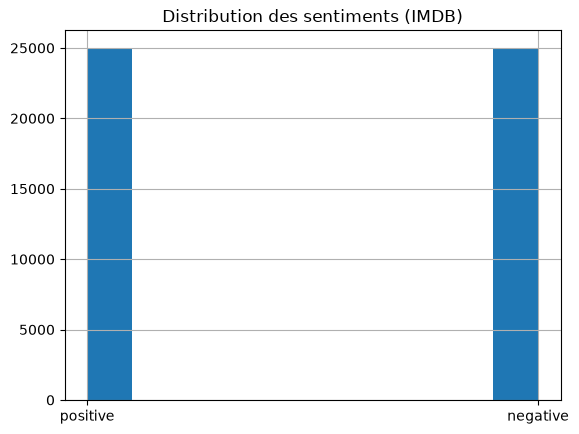

In [33]:
ax = train_df.sentiment.hist()
ax.set_title("Distribution des sentiments (IMDB)")
plt.savefig(RESULTS_DIR / "fig_distribution_sentiments.png", dpi=120, bbox_inches="tight")
plt.show()

On divise les données en deux segments :
- **80 % → `examples_df`** : réservoir dans lequel on puise les exemples *few-shot* ;
- **20 % → `gold_examples_df`** : réservoir d'**exemples de référence (gold examples)** pour évaluer les prompts.

In [34]:
examples_df, gold_examples_df = train_test_split(
    train_df, test_size=0.2, random_state=42
)

In [35]:
(examples_df.shape, gold_examples_df.shape)

((40000, 3), (10000, 3))

Pour cette session, on tire **20 gold examples** avec `random_state=42` : le tirage est aléatoire mais identique
d'une exécution à l'autre. On se limite à 20 pour garder des temps d'exécution (et une consommation de quota) faibles ;
en pratique, plus d'exemples de référence donnent une estimation plus robuste.

In [36]:
columns = ['text', 'sentiment']
gold_examples = (
    gold_examples_df.loc[:, columns]
    .sample(20, random_state=42)
    .to_json(orient='records')
)

In [37]:
json.loads(gold_examples)[0]

{'text': 'the tortuous emotional impact is degrading, whether adult or adolescent the personal values shown in this movie belong in a bad psychodrama if anywhere at all. This movie has a plot, but it is all evil from start to end. This is no way for people to act and degrades both sexes all the way through the movie. teen killing - bad preteen sex - bad emotional battering - bad animal cruelty - bad psychological torture - bad parental neglect - bad the only merit if any is the excellent color shots of contrasting red, blond and green leaves a bad feeling for anyone that respects life and peace, what a bad mistake to make, or to watch... it is UGLY',
 'sentiment': 'negative'}

In [38]:
# Répartition des sentiments parmi les 20 gold examples
pd.DataFrame(json.loads(gold_examples)).sentiment.value_counts()

sentiment
negative    11
positive     9
Name: count, dtype: int64

In [39]:
# Sauvegarde du jeu de référence au format JSON (réutilisable pour de futures itérations)
Path("data").mkdir(exist_ok=True)
with open("data/gold_examples.json", "w", encoding="utf-8") as f:
    json.dump(json.loads(gold_examples), f, ensure_ascii=False, indent=2)
print("Sauvegardé : data/gold_examples.json")

Sauvegardé : data/gold_examples.json


## Étape 3 : Élaborer le prompt

### Prompt 1 : Zero-shot

In [40]:
zero_shot_system_message = """
Classify the sentiment of movie reviews presented in the input as 'positive' or 'negative'
Movie reviews will be delimited by triple backticks in the input.
Answer only 'positive' or 'negative'
Do not explain your answer.
"""

In [41]:
zero_shot_prompt = [{'role': 'system', 'content': zero_shot_system_message}]

Le message *user* contient l'avis délimité par des triples backticks :

In [42]:
user_message_template = """```{movie_review}```"""

### Prompt 2 : Few-shot

Le message système ne change pas par rapport au zero-shot ; on l'enrichit avec des exemples *few-shot*
échantillonnés dans `examples_df`.

In [43]:
few_shot_system_message = """
Classify the sentiment of movie reviews presented in the input as 'positive' or 'negative'
Movie reviews will be delimited by triple backticks in the input.
Answer only 'positive' or 'negative'
Do not explain your answer.
"""

In [44]:
positive_reviews = (examples_df.sentiment == 'positive')
negative_reviews = (examples_df.sentiment == 'negative')

In [45]:
(positive_reviews.shape, negative_reviews.shape)

((40000,), (40000,))

In [46]:
columns = ['text', 'sentiment']
positive_examples = examples_df.loc[positive_reviews, columns].sample(4)
negative_examples = examples_df.loc[negative_reviews, columns].sample(4)

In [47]:
positive_examples

,text,sentiment
39650,I have copied my video of this on to DVD so th...,positive
4888,Probably the most accurate Stephen King adapti...,positive
38417,I revisited Grand Canyon earlier this year whe...,positive
24394,I picked this one up on a whim from the librar...,positive


In [48]:
negative_examples

,text,sentiment
17676,A bad movie ABOUT a bad movie. Is that origina...,negative
32483,This is a film that has garnered any interest ...,negative
29052,I've seen thousands of movies and have never w...,negative
39123,"Please, someone stop Ben Stiller from acting i...",negative


Sélectionner des échantillons aléatoires ne suffit pas : les exemples d'un prompt sont sujets à des biais connus :
- **biais de l'étiquette majoritaire** : le modèle tend à répondre l'étiquette la plus fréquente parmi les exemples ;
- **biais de récence** : les exemples situés vers la fin du prompt influencent davantage la réponse.

Pour les éviter, on construit un ensemble d'exemples **équilibré** (autant de positifs que de négatifs)
et présenté dans un **ordre aléatoire**. La fonction suivante implémente ce flux :

In [49]:
def create_examples(dataset, n=4):
    positive_reviews = (dataset.sentiment == 'positive')
    negative_reviews = (dataset.sentiment == 'negative')
    columns_to_select = ['text', 'sentiment']
    positive_examples = dataset.loc[positive_reviews, columns_to_select].sample(n)
    negative_examples = dataset.loc[negative_reviews, columns_to_select].sample(n)
    examples = pd.concat([positive_examples, negative_examples])
    # sampling without replacement is equivalent to random shuffling
    randomized_examples = examples.sample(2*n, replace=False)
    return randomized_examples.to_json(orient='records')

In [50]:
examples = create_examples(examples_df, 2)

In [51]:
json.loads(examples)

[{'text': 'Given the subject matter of drug addiction Down to the Bone almost can\'t help but be a rather depressing film. But depressing doesn\'t necessarily have to mean bad. Unfortunately in this case it is in fact pretty bad. The film has some good things going for it, most notably the quality performance of Vera Farmiga in the central role of Irene, a working mom struggling with a cocaine addiction. But there isn\'t enough good here to outweigh the bad. The film\'s failings lie mainly with the story, which fails to captivate and never really seems to get going. Irene goes to rehab and comes home to a clueless husband who has no idea how to support her attempt to kick her habit. Irene grows close to another recovering addict, a male nurse from her rehab center. Complications ensue. But the story never really sparks to life. It doesn\'t seem as if the movie is really going anywhere. You can say it\'s a stark, realistic look at the day-to-day struggles of an addict. Maybe so but in t

On assemble ensuite le prompt few-shot : message système + paires (*user* : avis, *assistant* : sentiment).
Avec Gemini, LangChain convertit automatiquement le rôle `system` en *system instruction* et le rôle
`assistant` en rôle `model`.

In [52]:
def create_prompt(system_message, examples, user_message_template):
    few_shot_prompt = [{'role': 'system', 'content': system_message}]
    for example in json.loads(examples):
        example_review = example['text']
        example_sentiment = example['sentiment']
        few_shot_prompt.append(
            {
                'role': 'user',
                'content': user_message_template.format(movie_review=example_review)
            }
        )
        few_shot_prompt.append(
            {
                'role': 'assistant',
                'content': f"{example_sentiment}"
            }
        )
    return few_shot_prompt

In [53]:
few_shot_prompt = create_prompt(
    few_shot_system_message,
    examples,
    user_message_template
)

In [54]:
# Aperçu du prompt few-shot (contenus tronqués pour l'affichage)
[{'role': m['role'], 'content': m['content'][:70] + ('...' if len(m['content']) > 70 else '')}
 for m in few_shot_prompt]

[{'role': 'system',
  'content': "\nClassify the sentiment of movie reviews presented in the input as 'po..."},
 {'role': 'user',
  'content': '```Given the subject matter of drug addiction Down to the Bone almost ...'},
 {'role': 'assistant', 'content': 'negative'},
 {'role': 'user',
  'content': '```please why not put this fantastic film on DVD,i have been searching...'},
 {'role': 'assistant', 'content': 'positive'},
 {'role': 'user',
  'content': '```This is what I was expecting when star trek DS9 premiered. Not to s...'},
 {'role': 'assistant', 'content': 'positive'},
 {'role': 'user',
  'content': '```What of Domino did I hate over everything, and I mean everything, e...'},
 {'role': 'assistant', 'content': 'negative'}]

### Prompt 3 : Chain-of-Thought

On ajoute au message système few-shot des **instructions détaillées étape par étape**, en demandant au modèle
de réfléchir soigneusement avant d'attribuer un sentiment. Les exemples restent les mêmes ; seul le message système change.

In [55]:
cot_system_message = """
Classify the sentiment of movie reviews presented in the input as 'positive' or 'negative'
Movie reviews will be delimited by triple backticks ``` in the input.
Answer only 'positive' or 'negative'
Do not explain your answer.

Instructions:
1. Carefully read the text of the review and think through the options for sentiment provided
2. Consider the overall sentiment of the review and estimate the probability of the review being positive

To reiterate, your answer should strictly only contain the label: positive or negative
"""

In [56]:
cot_few_shot_prompt = create_prompt(
    cot_system_message,
    examples,
    user_message_template
)

**Taille des prompts** (approximation avec `tiktoken`) : le few-shot et le CoT sont beaucoup plus longs que le
zero-shot, donc plus coûteux à chaque appel.

In [57]:
def count_prompt_tokens(prompt):
    return sum(len(tokenizer.encode(m['content'])) for m in prompt)

prompt_sizes = pd.Series({
    "Zero-shot": count_prompt_tokens(zero_shot_prompt),
    "Few-shot (4 exemples)": count_prompt_tokens(few_shot_prompt),
    "CoT few-shot (4 exemples)": count_prompt_tokens(cot_few_shot_prompt),
}, name="tokens (approx.)")
prompt_sizes

Zero-shot                      49
Few-shot (4 exemples)        2014
CoT few-shot (4 exemples)    2071
Name: tokens (approx.), dtype: int64

## Step 4 : Evaluate Prompts

Nous avons trois prompts à évaluer à l'aide des **gold labels**. La fonction `evaluate_prompt` envoie chaque
gold example au modèle, compare la prédiction à la vérité terrain et renvoie le **micro-F1**.

**Adaptations pour Gemini :**
- on lit la réponse avec `response.text` : avec les modèles Gemini 3, `response.content` peut être une liste de blocs
  (et non une chaîne), ce qui ferait échouer `.strip()` dans le code du cours ;
- un **cache** sur disque (`cache/gemini_cache.json`) mémorise chaque réponse : si une cellule est relancée ou si le
  quota est atteint en cours de route, les requêtes déjà faites ne sont pas renvoyées (économie de quota) ;
- les erreurs d'API sont comptées et signalées.

In [58]:
import hashlib

USE_CACHE = True
CACHE_PATH = Path("cache/gemini_cache.json")
CACHE_PATH.parent.mkdir(exist_ok=True)
_cache = json.loads(CACHE_PATH.read_text(encoding="utf-8")) if CACHE_PATH.exists() else {}


def invoke_with_cache(model, messages):
    """Appelle le modèle et renvoie le texte de la réponse (avec cache disque)."""
    model_name = getattr(model, "model", str(model))
    key = hashlib.sha256(
        json.dumps({"model": model_name, "messages": messages}, ensure_ascii=False, sort_keys=True).encode("utf-8")
    ).hexdigest()
    if USE_CACHE and key in _cache:
        return _cache[key]
    response = model.invoke(messages)
    text = response.text if hasattr(response, "text") else str(response)
    if USE_CACHE:
        _cache[key] = text
        CACHE_PATH.write_text(json.dumps(_cache, ensure_ascii=False), encoding="utf-8")
    return text

In [59]:
def evaluate_prompt(prompt, gold_examples, user_message_template, model, return_predictions=False):
    model_predictions, ground_truths = [], []
    n_errors = 0

    for example in json.loads(gold_examples):
        gold_input = example['text']
        user_input = [
            {
                'role': 'user',
                'content': user_message_template.format(movie_review=gold_input)
            }
        ]
        try:
            response_content = invoke_with_cache(model, prompt + user_input)
            answer = response_content.strip().lower()
            if 'negative' in answer:
                prediction = 'negative'
            elif 'positive' in answer:
                prediction = 'positive'
            else:
                prediction = 'unknown'
            model_predictions.append(prediction)
            ground_truths.append(example['sentiment'])
            # print(prediction, example['sentiment'])
        except Exception as e:
            n_errors += 1
            print(e)
            continue

    if n_errors:
        print(f"⚠️ {n_errors} exemple(s) ignoré(s) à cause d'une erreur d'API")
    if not ground_truths:
        micro_f1_score = float("nan")
    else:
        micro_f1_score = f1_score(ground_truths, model_predictions, average="micro")
    if return_predictions:
        return micro_f1_score, ground_truths, model_predictions
    return micro_f1_score

### Évaluation des trois prompts (un seul tirage d'exemples)

In [60]:
zero_shot_f1, zs_truths, zs_preds = evaluate_prompt(
    zero_shot_prompt, gold_examples, user_message_template, llm, return_predictions=True)
zero_shot_f1

1.0

In [61]:
few_shot_f1, fs_truths, fs_preds = evaluate_prompt(
    few_shot_prompt, gold_examples, user_message_template, llm, return_predictions=True)
few_shot_f1

1.0

In [62]:
cot_f1, cot_truths, cot_preds = evaluate_prompt(
    cot_few_shot_prompt, gold_examples, user_message_template, llm, return_predictions=True)
cot_f1

0.95

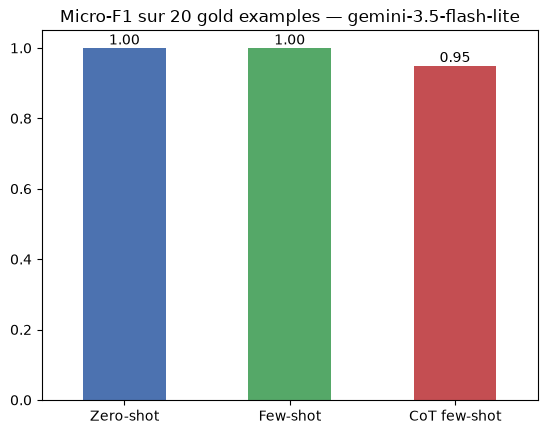

In [63]:
single_eval = pd.Series({"Zero-shot": zero_shot_f1, "Few-shot": few_shot_f1, "CoT few-shot": cot_f1},
                        name="micro-F1")
ax = single_eval.plot(kind="bar", ylim=(0, 1.05), rot=0, color=["#4C72B0", "#55A868", "#C44E52"])
ax.set_title(f"Micro-F1 sur 20 gold examples — {GEMINI_MODEL}")
for i, v in enumerate(single_eval):
    ax.text(i, v + 0.01, f"{v:.2f}", ha="center")
plt.savefig(RESULTS_DIR / "fig_scores_prompts.png", dpi=120, bbox_inches="tight")
plt.show()

**Matrices de confusion** (les réponses sont relues dans le cache : aucune requête supplémentaire) :

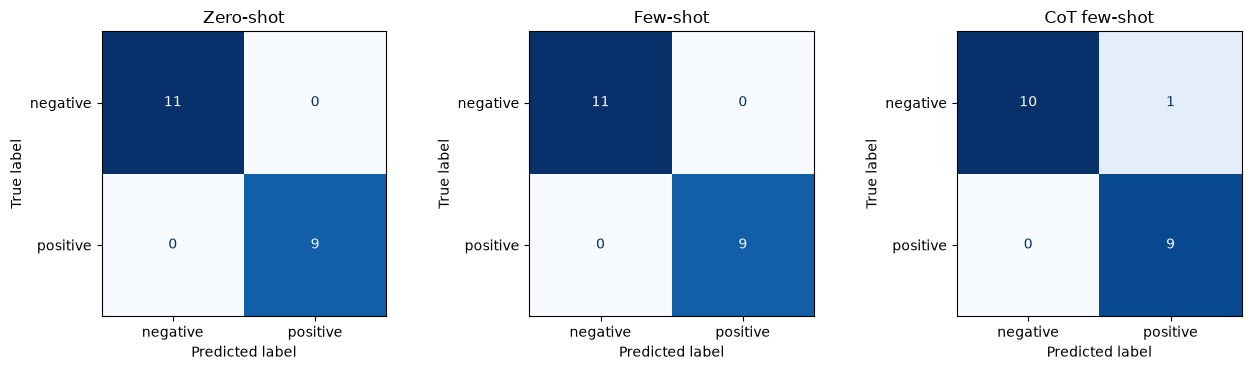

In [64]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, (name, t, p) in zip(axes, [("Zero-shot", zs_truths, zs_preds),
                                   ("Few-shot", fs_truths, fs_preds),
                                   ("CoT few-shot", cot_truths, cot_preds)]):
    labels = sorted(set(t) | set(p))
    ConfusionMatrixDisplay.from_predictions(t, p, labels=labels, ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(name)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "fig_matrices_confusion.png", dpi=120, bbox_inches="tight")
plt.show()

In [65]:
# Analyse d'erreurs : avis mal classés par le prompt zero-shot
gold_list = json.loads(gold_examples)
errors = [(g['sentiment'], p, g['text'][:200] + "...") for g, p in zip(gold_list, zs_preds) if g['sentiment'] != p]
print(f"{len(errors)} erreur(s) sur {len(zs_preds)}")
for truth, pred, txt in errors:
    print(f"\n[réel = {truth} | prédit = {pred}] {txt}")

0 erreur(s) sur 20


### Variabilité : plusieurs tirages d'exemples

Il ne s'agit là que **d'un seul** choix d'exemples. Les prompts few-shot et CoT dépendent de l'échantillon tiré :
on répète donc l'évaluation **10 fois** avec un nouveau tirage à chaque fois, pour estimer la moyenne et l'écart-type du micro-F1.

> **Correction par rapport au code du cours :** dans la boucle du support, `cot_few_shot_performance.append(few_shot_micro_f1)`
> ajoute le score **few-shot** à la liste CoT : le prompt CoT n'est jamais évalué. Ici, chaque tour évalue réellement
> les deux prompts avec les **mêmes** exemples.
>
> ⏱️ 10 tours × 2 prompts × 20 avis = **400 requêtes** (≈ 35 min à 12 requêtes/min). Si le quota journalier est atteint,
> relancez la cellule plus tard : le cache évite de refaire les requêtes déjà réussies. Pour aller plus vite, réduisez `num_eval_runs`.

In [66]:
num_eval_runs = 10
few_shot_performance, cot_few_shot_performance = [], []

for _ in tqdm(range(num_eval_runs)):
    # For each run create a new sample of examples
    examples = create_examples(examples_df)
    # Assemble the few shot prompt and the CoT prompt with these examples
    few_shot_prompt = create_prompt(few_shot_system_message, examples, user_message_template)
    cot_few_shot_prompt = create_prompt(cot_system_message, examples, user_message_template)
    # Evaluate prompt accuracy on gold examples
    few_shot_micro_f1 = evaluate_prompt(few_shot_prompt, gold_examples, user_message_template, llm)
    cot_few_shot_micro_f1 = evaluate_prompt(cot_few_shot_prompt, gold_examples, user_message_template, llm)
    few_shot_performance.append(few_shot_micro_f1)
    cot_few_shot_performance.append(cot_few_shot_micro_f1)

100%|██████████| 10/10 [51:54<00:00, 311.48s/it] 


In [67]:
mean_val = np.array(few_shot_performance).mean()
std_val = np.array(few_shot_performance).std()

In [68]:
print(f"Few-shot : f1_score Moyen= {mean_val}, Standard Deviation = {std_val} ")

Few-shot : f1_score Moyen= 0.99, Standard Deviation = 0.020000000000000018 


In [69]:
cot_mean_val = np.array(cot_few_shot_performance).mean()
cot_std_val = np.array(cot_few_shot_performance).std()
print(f"CoT      : f1_score Moyen= {cot_mean_val}, Standard Deviation = {cot_std_val} ")

CoT      : f1_score Moyen= 0.99, Standard Deviation = 0.020000000000000018 


In [70]:
runs_df = pd.DataFrame({"run": range(1, num_eval_runs + 1),
                        "few_shot_micro_f1": few_shot_performance,
                        "cot_few_shot_micro_f1": cot_few_shot_performance})
runs_df.to_csv(RESULTS_DIR / "runs_few_shot_cot.csv", index=False)
runs_df

,run,few_shot_micro_f1,cot_few_shot_micro_f1
0,1,0.95,1.00
1,2,1.00,1.00
2,3,1.00,0.95
3,4,0.95,1.00
4,5,1.00,1.00
5,6,1.00,1.00
6,7,1.00,0.95
7,8,1.00,1.00
8,9,1.00,1.00
9,10,1.00,1.00


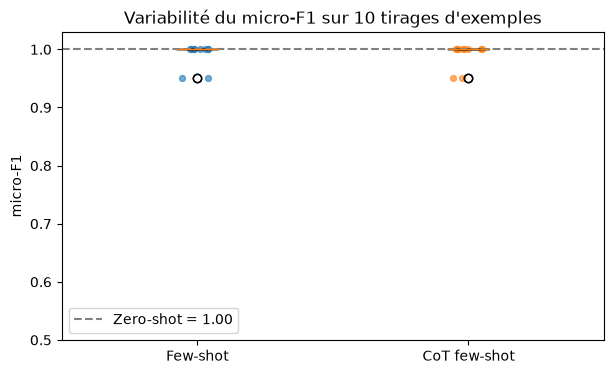

In [71]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.boxplot([few_shot_performance, cot_few_shot_performance])
ax.set_xticks([1, 2], ["Few-shot", "CoT few-shot"])
for i, perf in enumerate([few_shot_performance, cot_few_shot_performance], start=1):
    ax.scatter(np.random.normal(i, 0.04, len(perf)), perf, alpha=0.6, s=18)
ax.axhline(zero_shot_f1, ls="--", color="gray", label=f"Zero-shot = {zero_shot_f1:.2f}")
ax.set_ylim(min(0.5, min(few_shot_performance + cot_few_shot_performance) - 0.05), 1.03)
ax.set_ylabel("micro-F1")
ax.set_title(f"Variabilité du micro-F1 sur {num_eval_runs} tirages d'exemples")
ax.legend()
plt.savefig(RESULTS_DIR / "fig_variabilite_runs.png", dpi=120, bbox_inches="tight")
plt.show()

# 5. Synthèse des résultats

Tableau récapitulatif (également enregistré dans `resultats/resultats_evaluation.csv`).
Le bloc Markdown affiché à la fin peut être copié dans le rapport.

In [72]:
summary = pd.DataFrame({
    "Prompt": ["Zero-shot", "Few-shot", "CoT few-shot"],
    "micro-F1 (1 tirage)": [zero_shot_f1, few_shot_f1, cot_f1],
    f"micro-F1 moyen ({num_eval_runs} tirages)": [np.nan, mean_val, cot_mean_val],
    "écart-type": [np.nan, std_val, cot_std_val],
    "tokens du prompt (1 tirage, approx.)": [prompt_sizes.iloc[0], prompt_sizes.iloc[1], prompt_sizes.iloc[2]],
})
summary.to_csv(RESULTS_DIR / "resultats_evaluation.csv", index=False)
summary

,Prompt,micro-F1 (1 tirage),micro-F1 moyen (10 tirages),écart-type,"tokens du prompt (1 tirage, approx.)"
0,Zero-shot,1.00,NaN,NaN,49
1,Few-shot,1.00,0.99,0.02,2014
2,CoT few-shot,0.95,0.99,0.02,2071


In [73]:
def fmt(x):
    return "—" if pd.isna(x) else (f"{x:.3f}" if isinstance(x, float) else str(x))

lines = ["| " + " | ".join(summary.columns) + " |", "|" + "---|" * len(summary.columns)]
lines += ["| " + " | ".join(fmt(v) for v in row) + " |" for row in summary.itertuples(index=False)]
markdown_table = "\n".join(lines)
(RESULTS_DIR / "resultats_evaluation.md").write_text(
    f"Modèle : {GEMINI_MODEL} — {len(json.loads(gold_examples))} gold examples\n\n" + markdown_table + "\n",
    encoding="utf-8")
print(f"Modèle : {GEMINI_MODEL}\n")
print(markdown_table)

Modèle : gemini-3.5-flash-lite

| Prompt | micro-F1 (1 tirage) | micro-F1 moyen (10 tirages) | écart-type | tokens du prompt (1 tirage, approx.) |
|---|---|---|---|---|
| Zero-shot | 1.000 | — | — | 49 |
| Few-shot | 1.000 | 0.990 | 0.020 | 2014 |
| CoT few-shot | 0.950 | 0.990 | 0.020 | 2071 |


**Pistes d'interprétation** :
- Comparer le zero-shot aux prompts few-shot / CoT : les exemples apportent-ils un gain sur ce modèle ?
- Avec 20 gold examples, chaque erreur coûte 0,05 point de micro-F1 : des écarts de 0,05 ne sont pas forcément significatifs.
- L'écart-type mesure la sensibilité au choix des exemples few-shot.
- Mettre en regard la performance et le coût (nombre de tokens du prompt).